# Bounce paired Δ per visit and per pair, for the DZ terms of the 22/12 v-modes (v1)

**Author:** Aaron Roodman (with Claude)
**Date Created:** 2026-11-21
**Last Modified:** 2026-11-21
**Status:** In Progress
**Keywords:** bounce, paired Δ, DZ, 22/12, BLOCK-T720

## Description

For the BLOCK-T720 elevation sweep (reference 70 deg), one PDF page per DZ term.
Each page has one row per (night, leg):

- **left**: DZ_kj per visit vs time. A visits are blue circles and B visits red
  squares, filled if paired and open if not. Visits of other legs are grey. A line
  joins each pair.
- **right**: the per-pair B − A in pair order, with the median Δ, the ±err band and
  the ±1.4826 MAD band. This is the bounce pipeline's paired reduction, and it is
  checked against `run_bounce`.

The terms are all k = 1 terms, plus each k > 1 term that holds at least
`MODE_POWER_MIN` of the power of any of the 12 u-modes of the 22/12 SVD (126 × 22
normalized DZ sensitivity, 12 modes kept).

**Output:** `bounce_dz_pairs_summary.pdf` and `bounce_dz_pairs_summary.csv` in the
study run directory.

**Based on:** `bounce_delta_derivation_v4` (the DZ(1,4) version of these panels).

## Change Log

| Date | Author | Description |
|------|--------|-------------|
| 2026-11-21 | Aaron Roodman | Initial version |

## Table of Contents

1. [Parameters](#params)
2. [Setup & Imports](#setup)
3. [Data Access and term selection](#data)
4. [Pairs](#pairs)
5. [Pages](#pages)
6. [Save](#save)

<a id='params'></a>
## Parameters

In [1]:
DAY_OBS = [20260418, 20260419, 20260513, 20260709, 20260711, 20260713]
BOUNCE = 'T720_elevation'          # bounce name from analysis_config.yaml

PARAM_SET = 'danish_1_3'
MI_NAME = 'pathA_50_50_i_rbr_5rot'
MIW_VARIANT = 'd13-A_50_50_i_rbr_5rot'
MIW_BUILD = '20261028b'
MIN_DETECTORS = 160                # the bounce run's --min-detectors

MODE_POWER_MIN = 0.01              # k > 1 term kept if U[term, m]^2 >= this for any of the 12 u-modes
N_TERMS_EXPECTED = 29              # the reviewed selection (21 k = 1 terms + 8)
SAVE = True

from rubinwork.common import study_run
run = study_run('aos/bounce', 'dz_pairs_summary')

<a id='setup'></a>
## Setup & Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

from rubinwork import aos_state
from rubinwork.bounce import legs as bl
from rubinwork.bounce import analysis as ba
from rubinwork.common.utils import repo_root
from rubinwork.products import catalog
from lsst.ts.intrinsic.wavefront.ofc_svd import build_ofc_svd

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)


def paired_reduction(diffs):
    """The bounce reduction of per-pair differences.

    Parameters
    ----------
    diffs : `numpy.ndarray`
        Per-pair B − A differences, um of wavefront.

    Returns
    -------
    r : `dict`
        ``delta`` (median, um), ``sigma`` (1.4826 MAD, um), ``err``
        (1.2533 sigma / sqrt n, um), ``mean`` (um) and ``n``.
    """
    d = np.asarray(diffs, float)
    d = d[np.isfinite(d)]
    n = d.size
    delta = float(np.median(d))
    sigma = 1.4826 * float(np.median(np.abs(d - delta)))
    return {'n': n, 'delta': delta, 'sigma': sigma, 'err': 1.2533 * sigma / np.sqrt(n),
            'mean': float(np.mean(d))}

<a id='data'></a>
## Data Access and term selection

The fit table goes through the same bad-fit drop and quality cut as the bounce run.
The u-mode power of a term is `U[term, m]^2`; each u-mode's column sums to 1 over the
126 terms.

In [3]:
cfg = bl.resolve_config(PARAM_SET, MI_NAME,
                        analysis_config=repo_root() / 'aos' / 'analysis_config.yaml')
prefix = cfg['fit_prefix']
b = next(x for x in cfg['bounces'] if x['name'] == BOUNCE)
ft = ba.load_fit_table(catalog.path('miw', MIW_VARIANT, build=MIW_BUILD) / 'fits.parquet',
                       cfg, min_detectors=MIN_DETECTORS)
iZs = list(cfg['pupil_j_range']); kr = cfg['focal_k_range']
svd = build_ofc_svd(iZs, int(min(kr)), int(max(kr)), int(cfg['n_keep_reduced']), n_dof=list(aos_state.DOF22),
                    ofc_normalization_yaml=cfg['ofc_normalization_yaml'])
KJ = list(svd.kj_grid); NK = svd.n_keep_eff
P = svd.U_eff ** 2                                   # (term, u-mode), dimensionless
k1 = [(k, j) for k, j in KJ if k == 1]
extra = [KJ[t] for t in range(len(KJ)) if KJ[t][0] > 1 and P[t].max() >= MODE_POWER_MIN]
TERMS = k1 + sorted(extra)
assert len(TERMS) == N_TERMS_EXPECTED, f'{len(TERMS)} terms, not the reviewed {N_TERMS_EXPECTED}'
sel = [KJ.index(t) for t in TERMS]
cap = P[sel].sum(0)
print(f'{len(TERMS)} terms: {len(k1)} with k = 1 and {len(extra)} with k > 1: '
      f'{[f"DZ{t}" for t in sorted(extra)]}')
print(f'u-mode power kept by the selection, u1..u{NK}: {np.round(cap, 3).tolist()} (dimensionless; '
      'over the u-mode total)')
top = pd.DataFrame({'term': [f'DZ{t}' for t in TERMS], 'max_umode_power': P[sel].max(1),
                    'at_umode': [f'u{m + 1}' for m in P[sel].argmax(1)]})
top.round(3)

  dropping 11 bad-flagged visits (z1toz6_bad_fit)


        Use pytest instead. [astropy.tests.runner]
        Use pytest instead.


        Use pytest instead. [astropy.utils.decorators]
        Use pytest instead.


INFO:lsst.ts.utils.tai:Update leap second table


INFO:lsst.ts.utils.tai:current_tai uses the system TAI clock


  quality cut (min_detectors=160): 1575/2012 visits kept


29 terms: 21 with k = 1 and 8 with k > 1: ['DZ(2, 4)', 'DZ(2, 5)', 'DZ(2, 6)', 'DZ(2, 8)', 'DZ(3, 4)', 'DZ(3, 5)', 'DZ(3, 6)', 'DZ(3, 7)']
u-mode power kept by the selection, u1..u12: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.999, 0.999, 0.998, 0.998, 0.999] (dimensionless; over the u-mode total)


,term,max_umode_power,at_umode
0,"DZ(1, 4)",1.000,u1
1,"DZ(1, 5)",0.972,u6
2,"DZ(1, 6)",0.972,u7
3,"DZ(1, 7)",0.590,u9
4,"DZ(1, 8)",0.590,u8
5,"DZ(1, 9)",0.948,u11
6,"DZ(1, 10)",0.947,u10
7,"DZ(1, 11)",0.704,u12
8,"DZ(1, 12)",0.003,u7
9,"DZ(1, 13)",0.003,u6


<a id='pairs'></a>
## Pairs

For each night, `run_bounce(..., day_obs=night)` gives the A mask, each B leg's mask,
the pairs and the pipeline Δ for every selected term. The pairs do not depend on the
term.

In [4]:
dobs = np.asarray(ft['day_obs']).astype(int)
seq = np.asarray(ft['seq_num']).astype(int)
mjd = np.asarray(ft['mjd'], float)
prog = bl.bounce_program_mask(ft, b)
ks_sel = sorted({k for k, _ in TERMS}); js_sel = sorted({j for _, j in TERMS})
legs = []
for d in DAY_OBS:
    rb = bl.run_bounce(ft, b, prefix, ks_sel, js_sel, day_obs=d)
    night = (dobs == d) & prog
    if not night.any():
        continue
    t0 = mjd[night].min()
    for lab, cb in rb['comparisons'].items():
        if cb['pairs']:
            legs.append({'night': d, 'leg': lab, 'b_value_deg': bl.leg_b_value(lab), 'night_mask': night,
                         'ref_mask': rb['ref_mask'], 'comp_mask': cb['comp_mask'],
                         'pairs': cb['pairs'], 'deltas': cb['deltas'], 't0': t0})
legs.sort(key=lambda L: (L['b_value_deg'], L['night']))
print(f'{len(legs)} (night, leg): ' + ', '.join(f"{L['night']} {L['leg']} ({len(L['pairs'])} pairs)" for L in legs))

rows = []
for k, j in TERMS:
    y = np.asarray(ft[f'{prefix}_z{j}_c{k}'], float)
    for L in legs:
        r, c = np.array(L['pairs']).T
        red = paired_reduction(y[c] - y[r])
        pipe = L['deltas'][(k, j)]
        assert np.isclose(red['delta'], pipe['delta']) and np.isclose(red['err'], pipe['err']), (k, j, L['leg'])
        rows.append({'term': f'DZ({k},{j})', 'k': k, 'j': j, 'night': L['night'], 'leg': L['leg'],
                     'b_value_deg': L['b_value_deg'], 'delta_um': red['delta'], 'err_um': red['err'],
                     'sigma_1p4826mad_um': red['sigma'], 'mean_um': red['mean'], 'n_pairs': red['n']})
summ = pd.DataFrame(rows)
print('paired Δ reproduces the pipeline for every term and leg')
summ.pivot(index='term', columns=['night', 'leg'], values='delta_um').loc[[f'DZ({k},{j})' for k, j in TERMS]].round(4)

7 (night, leg): 20260713 Elev=30 (5 pairs), 20260418 Elev=40 (6 pairs), 20260419 Elev=40 (10 pairs), 20260513 Elev=40 (8 pairs), 20260711 Elev=50 (6 pairs), 20260709 Elev=60 (4 pairs), 20260713 Elev=75 (6 pairs)
paired Δ reproduces the pipeline for every term and leg


night,20260713,20260418,20260419,20260513,20260711,20260709,20260713
leg,Elev=30,Elev=40,Elev=40,Elev=40,Elev=50,Elev=60,Elev=75
term,,,,,,,
"DZ(1,4)",0.3337,-0.1072,-0.1445,0.0323,0.2071,0.0486,-0.0032
"DZ(1,5)",0.2126,-0.0242,-0.1749,-0.2108,0.0620,-0.0667,0.0594
"DZ(1,6)",0.0564,-0.0432,0.1714,0.1262,0.3126,0.1614,-0.1108
"DZ(1,7)",0.2505,0.2214,0.2092,0.2789,0.1085,0.0963,-0.0776
"DZ(1,8)",0.1427,0.0463,0.0370,0.0911,0.0858,0.0430,0.0282
"DZ(1,9)",0.1079,0.1700,0.0875,0.1366,0.0414,0.0316,-0.0203
"DZ(1,10)",-0.0542,0.0110,0.0580,-0.0104,-0.1639,-0.0838,0.0135
"DZ(1,11)",0.0110,0.0067,0.0088,0.0124,-0.0229,0.0024,-0.0014


<a id='pages'></a>
## Pages

One page per term; rows are (night, leg), sorted by B elevation.

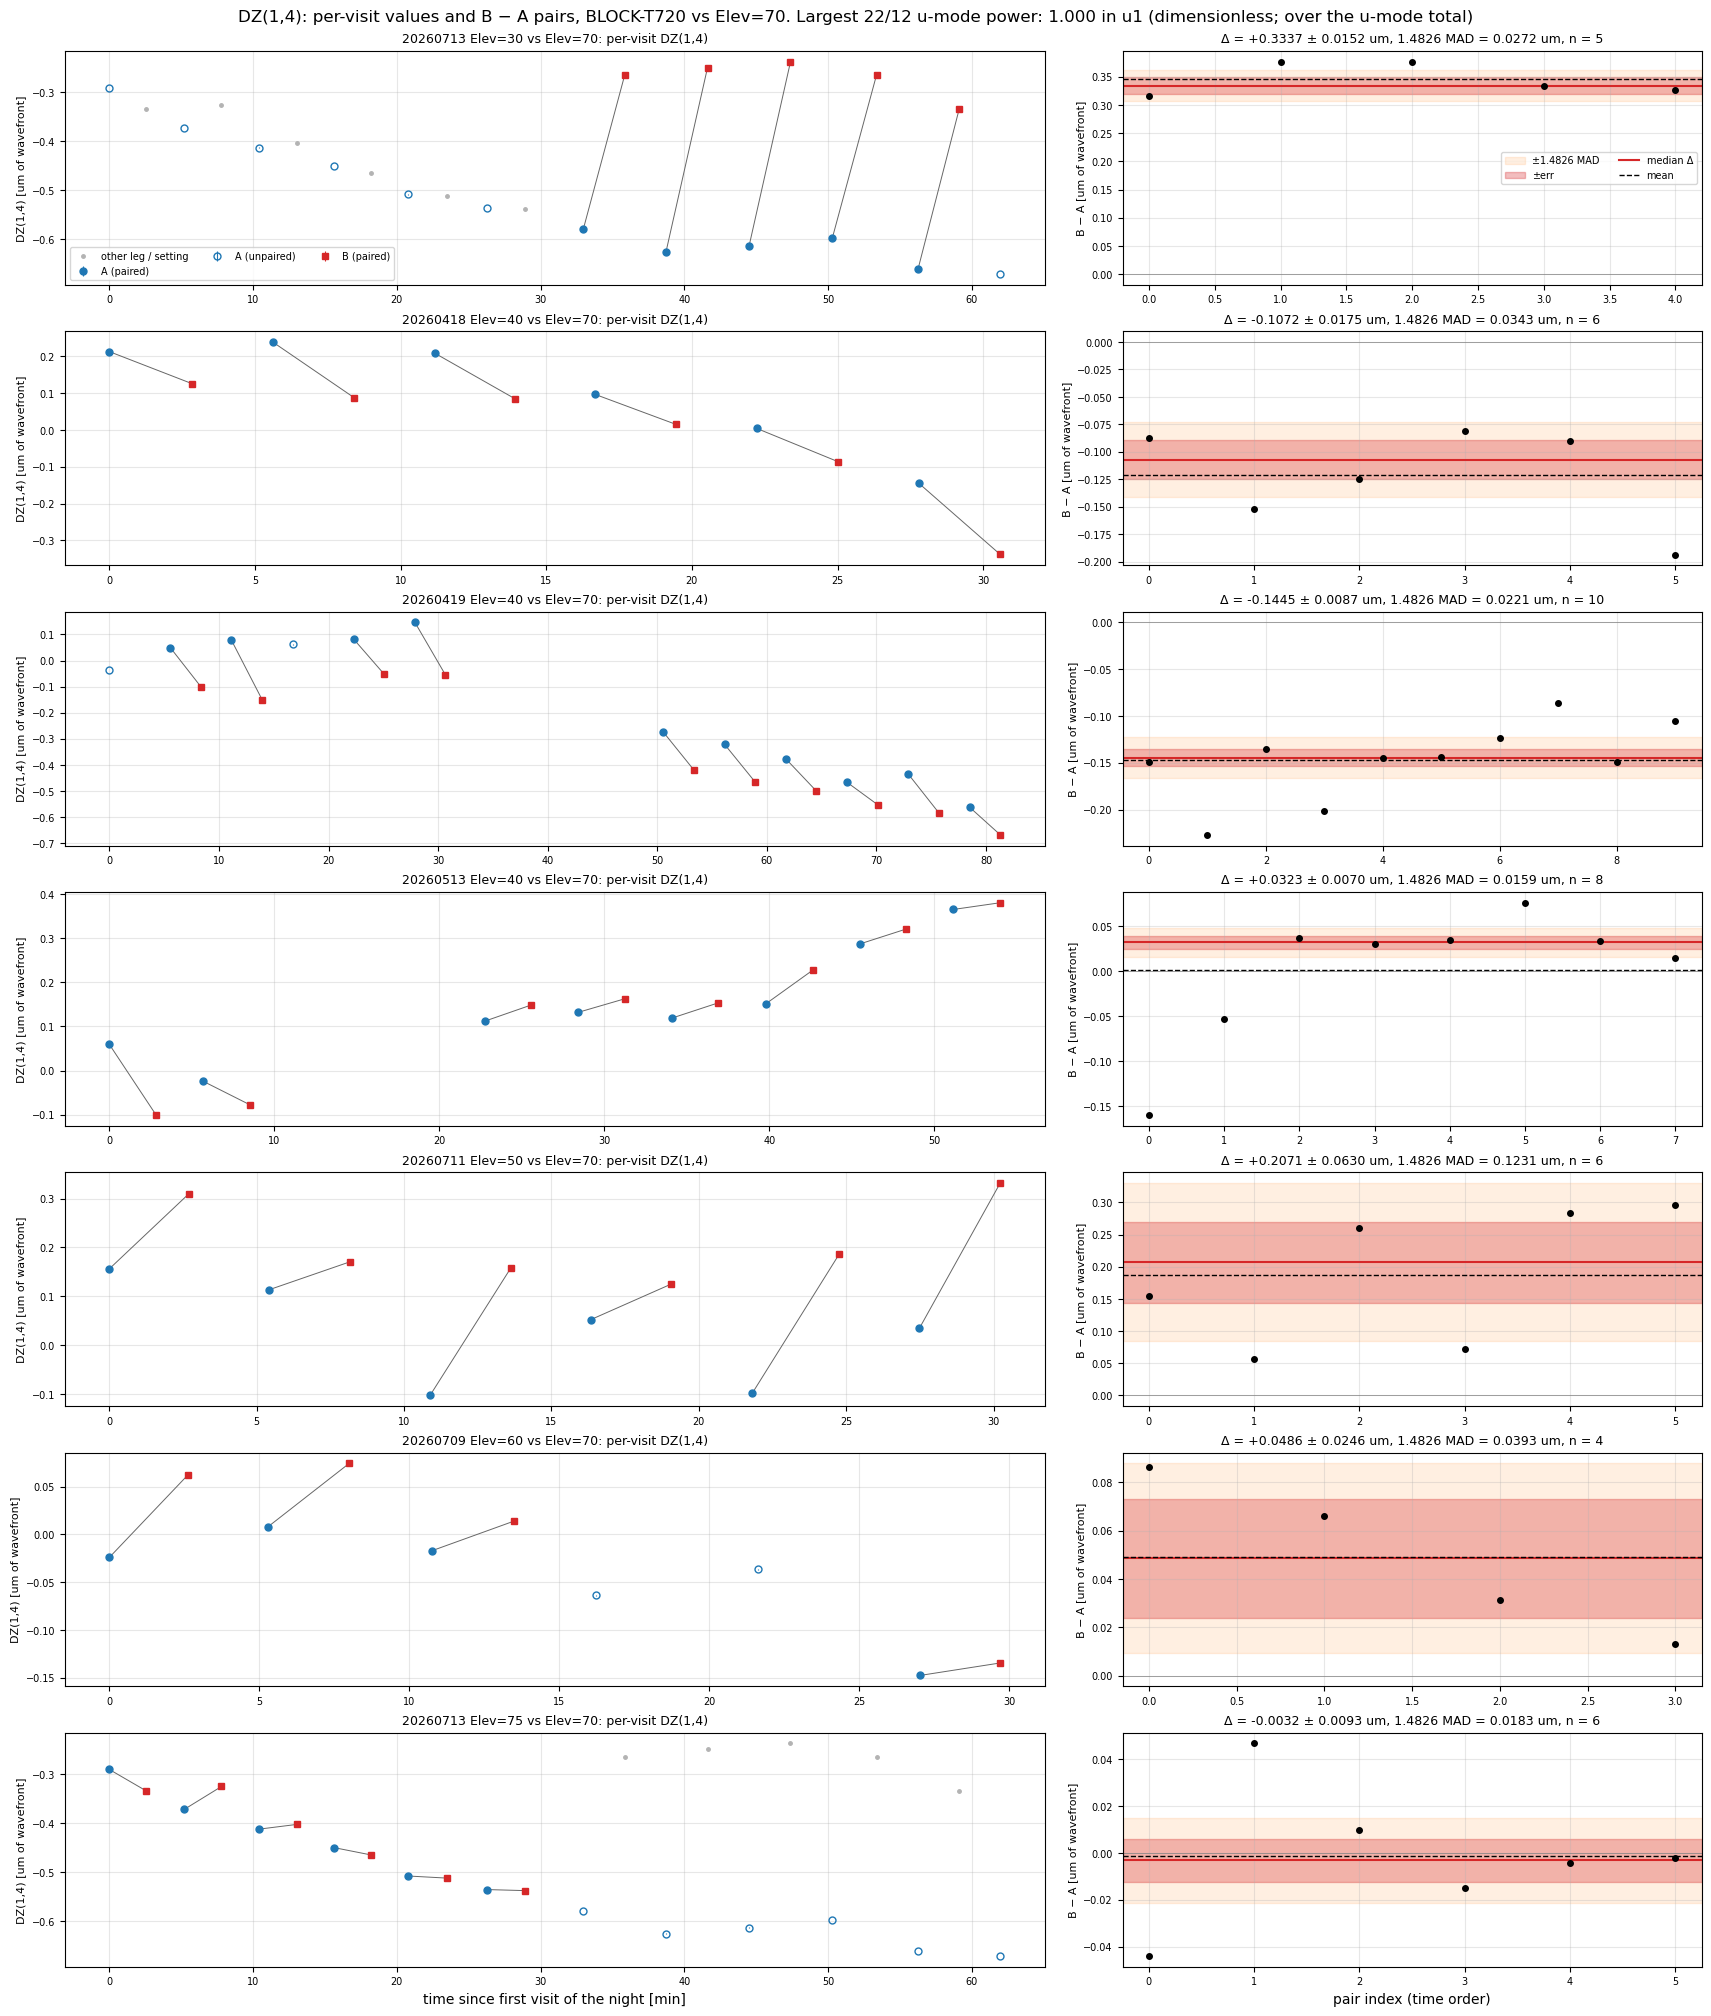

In [5]:
ref_lab = b['reference']['label']


def term_page(k, j):
    col = f'{prefix}_z{j}_c{k}'
    y = np.asarray(ft[col], float)
    ye = np.asarray(ft[col + '_err'], float) if col + '_err' in ft.colnames else np.full(len(y), np.nan)
    fig, axs = plt.subplots(len(legs), 2, figsize=(17, 2.75 * len(legs) + 0.8), layout='constrained',
                            gridspec_kw={'width_ratios': [2.2, 1.3]}, squeeze=False)
    for (a0, a1), L in zip(axs, legs):
        t = (mjd - L['t0']) * 1440.0
        paired = {i for p in L['pairs'] for i in p}
        nm = L['night_mask']
        oth = nm & ~L['ref_mask'] & ~L['comp_mask']
        a0.plot(t[oth], y[oth], '.', color='0.7', ms=5, label='other leg / setting')
        for s, mask, mk, cl in (('A', L['ref_mask'], 'o', '#1f77b4'), ('B', L['comp_mask'], 's', '#d62728')):
            ix = np.nonzero(nm & mask)[0]
            for is_p, fc in ((True, cl), (False, 'none')):
                w = [i for i in ix if (i in paired) == is_p]
                if w:
                    a0.errorbar(t[w], y[w], yerr=ye[w], fmt=mk, ms=5, mfc=fc, mec=cl, color=cl,
                                elinewidth=0.8, label=f"{s} ({'paired' if is_p else 'unpaired'})")
        for r, c in L['pairs']:
            a0.plot([t[r], t[c]], [y[r], y[c]], '-', color='0.4', lw=0.7)
        a0.set_ylabel(f'DZ({k},{j}) [um of wavefront]', fontsize=8)
        a0.set_title(f"{L['night']} {L['leg']} vs {ref_lab}: per-visit DZ({k},{j})", fontsize=9)
        a0.grid(alpha=0.3); a0.tick_params(labelsize=7)
        if L is legs[0]:
            a0.legend(fontsize=7, ncols=3)

        rr, cc = np.array(L['pairs']).T
        dd = y[cc] - y[rr]; red = paired_reduction(dd)
        a1.axhspan(red['delta'] - red['sigma'], red['delta'] + red['sigma'], color='#ff7f0e', alpha=0.12,
                   label='±1.4826 MAD')
        a1.axhspan(red['delta'] - red['err'], red['delta'] + red['err'], color='#d62728', alpha=0.3, label='±err')
        a1.axhline(red['delta'], color='#d62728', lw=1.5, label='median Δ')
        a1.axhline(red['mean'], color='k', lw=1, ls='--', label='mean')
        a1.plot(np.arange(len(dd)), dd, 'ko', ms=4)
        a1.axhline(0, color='gray', lw=0.5)
        a1.set_ylabel('B − A [um of wavefront]', fontsize=8)
        a1.set_title(f"Δ = {red['delta']:+.4f} ± {red['err']:.4f} um, 1.4826 MAD = {red['sigma']:.4f} um, "
                     f"n = {red['n']}", fontsize=9)
        a1.grid(alpha=0.3); a1.tick_params(labelsize=7)
        if L is legs[0]:
            a1.legend(fontsize=7, ncols=2)
    axs[-1, 0].set_xlabel('time since first visit of the night [min]')
    axs[-1, 1].set_xlabel('pair index (time order)')
    t_ = KJ.index((k, j))
    fig.suptitle(f'DZ({k},{j}): per-visit values and B − A pairs, BLOCK-T720 vs {ref_lab}. '
                 f'Largest 22/12 u-mode power: {P[t_].max():.3f} in u{P[t_].argmax() + 1} '
                 '(dimensionless; over the u-mode total)')
    return fig


figs = []
for k, j in TERMS:
    figs.append(term_page(k, j))
    if (k, j) == TERMS[0]:
        plt.show()
    else:
        plt.close(figs[-1])

<a id='save'></a>
## Save

In [6]:
if SAVE:
    out = run.path / 'bounce_dz_pairs_summary.pdf'
    with PdfPages(str(out)) as pdf:
        for f in figs:
            pdf.savefig(f, bbox_inches='tight')
    summ.to_csv(run.path / 'bounce_dz_pairs_summary.csv', index=False)
    print(f'wrote {out}: {len(figs)} pages, one per term')

wrote /sdf/group/rubin/u/roodman/LSST/rubin-work/studies/aos/bounce/20261121_dz_pairs_summary/bounce_dz_pairs_summary.pdf: 29 pages, one per term
